# 06 — Importance des variables et explicabilité

**Rôle :** comprendre *pourquoi* les modèles décident, avec cinq méthodes (`src/run_analysis.py`) :

| Méthode | Principe | Limite |
|---|---|---|
| Impureté (Gini) — RF | baisse moyenne d'impureté apportée par la variable | biaisée vers les variables à nombreuses valeurs |
| Gain — XGBoost | amélioration moyenne de la perte aux splits | propre au modèle |
| **SHAP** (TreeSHAP) | valeur de Shapley : contribution exacte de chaque variable à chaque prédiction | coûteux hors arbres |
| Permutation | baisse de F1 sur le test quand on mélange la variable | sous-estime les variables corrélées |
| Information mutuelle | dépendance statistique variable ↔ cible, sans modèle | univariée |

Les valeurs SHAP sont calculées nativement par XGBoost (`pred_contribs=True`) : pas de dépendance supplémentaire.

In [1]:
# Configuration : le notebook s'exécute depuis notebooks/, on ajoute la racine du dépôt au chemin
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src import config as C
from src import visualization as V
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
print('Racine du projet :', ROOT.name)

Racine du projet : Network-Intrusion-Detection-System


In [2]:
RUN = False
from src import run_analysis as RA
if RUN or not (C.METRICS_DIR / 'analysis.json').exists():
    RA.main()
imp = pd.read_csv(C.METRICS_DIR / 'feature_importance.csv', index_col=0)
display(imp[['mean_rank', 'shap_xgboost', 'permutation_best', 'impurity_rf', 'gain_xgboost', 'mutual_info']].head(20).round(4))

1) Statistiques EDA


2) Comparaison statistique


[binary] Friedman χ²=60.38 p=1.01e-07 | McNemar svm vs extra_trees p=1


[multiclass] Friedman χ²=50.82 p=4.46e-07 | McNemar random_forest vs xgboost p=0.589
3) Importance des features


4) Courbes d'apprentissage
5) Ablation


  ablation aucun (référence)                  F1 bin=0.9879 | F1 macro=0.6825


... (8 outputs left out)

  PCAP demo_unsw_testbed  profil portable F1=0.495 rappel=0.347 FPR=0.097 catégorie=0.325


  PCAP demo_modern_ttl    profil full     F1=0.000 rappel=0.000 FPR=0.000 catégorie=0.415


  PCAP demo_modern_ttl    profil portable F1=0.480 rappel=0.351 FPR=0.160 catégorie=0.348
Terminé en 196s


,mean_rank,shap_xgboost,permutation_best,impurity_rf,gain_xgboost,mutual_info
feature,,,,,,
sttl,1.8,4.3392,0.0633,0.5330,0.8638,0.6025
ct_state_ttl,2.0,2.7910,0.1874,0.2796,0.0437,0.5907
dttl,8.0,0.0524,0.3011,0.0203,0.0038,0.5089
dbytes,8.2,0.2471,0.0754,0.0011,0.0032,0.4550
tcprtt,10.4,0.1978,0.0004,0.0062,0.0017,0.3548
sbytes,10.8,0.1248,0.0237,0.0012,0.0014,0.5434
byte_ratio,13.5,0.1995,0.0000,0.0013,0.0016,0.5305
bytes_per_pkt,14.7,0.0728,0.0000,0.0024,0.0020,0.4973
dmeansz,15.1,0.0927,0.0000,0.0254,0.0015,0.3955


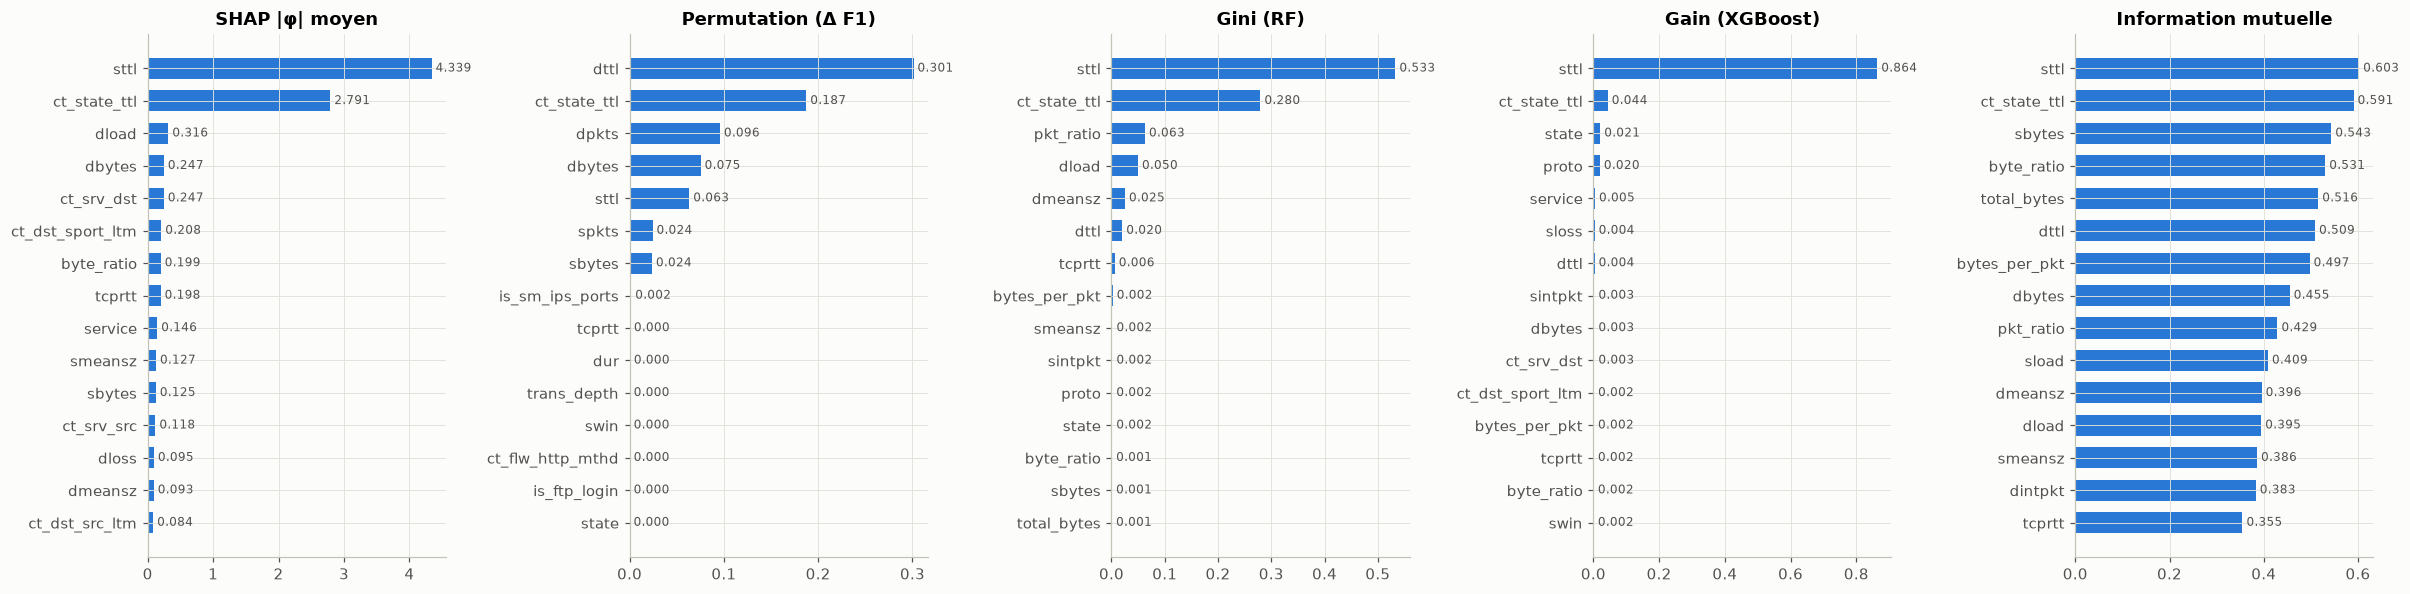

,rank_impurity_rf,rank_gain_xgboost,rank_shap_xgboost,rank_permutation_best,rank_mutual_info
rank_impurity_rf,1.00,0.70,0.76,0.08,0.85
rank_gain_xgboost,0.70,1.00,0.75,0.13,0.57
rank_shap_xgboost,0.76,0.75,1.00,0.03,0.70
rank_permutation_best,0.08,0.13,0.03,1.00,0.17
rank_mutual_info,0.85,0.57,0.70,0.17,1.00


In [3]:
methods = [('shap_xgboost', 'SHAP |φ| moyen'), ('permutation_best', 'Permutation (Δ F1)'), ('impurity_rf', 'Gini (RF)'),
           ('gain_xgboost', 'Gain (XGBoost)'), ('mutual_info', 'Information mutuelle')]
fig, axes = plt.subplots(1, 5, figsize=(22, 5.5))
for ax, (m, l) in zip(axes, methods):
    s = imp[m].sort_values(ascending=False).head(15)
    V.barh(ax, s.index, s.values, fmt='{:.3f}'); ax.set_title(l)
plt.tight_layout(); V.save(fig, '06_feature_importance_methods'); plt.show()
agree = pd.read_csv(C.METRICS_DIR / 'feature_importance_rank_agreement.csv', index_col=0)
display(agree.round(2))

## Résumé SHAP (style *beeswarm*) et explication locale

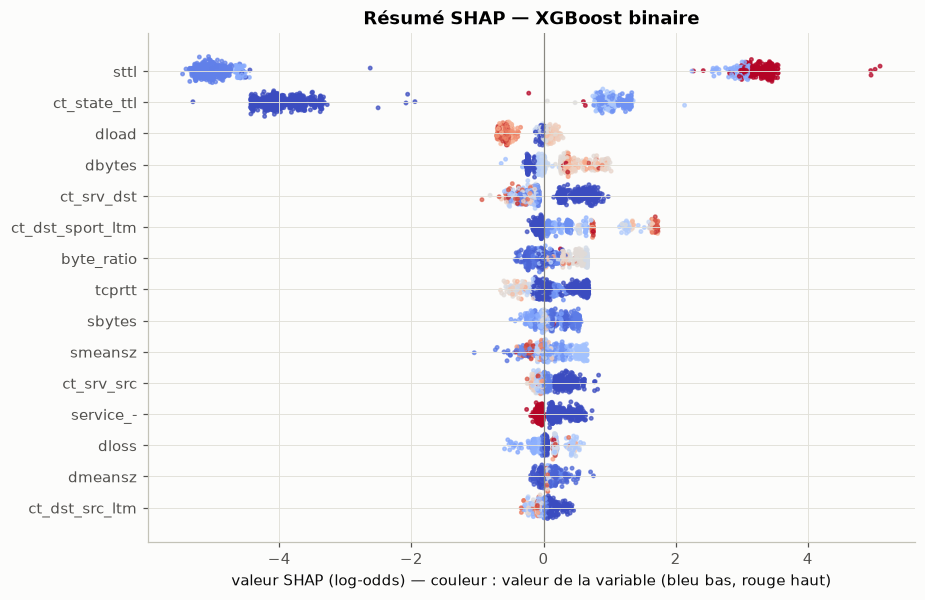

In [4]:
import joblib
from src.evaluation import explain as EX
reg = json.loads((C.REGISTRY_FILE).read_text(encoding='utf-8'))
xgb = joblib.load(C.ALL_MODELS_DIR / reg['models']['full']['binary']['xgboost']['file'])
test = pd.read_csv(C.TEST_FILE, low_memory=False)
sub = test.sample(1500, random_state=3)
from src.preprocessing import feature_frame
vals, names, base = EX.shap_values(xgb, sub)
Z = xgb.named_steps['prep'].transform(feature_frame(sub))
order = np.argsort(np.abs(vals).mean(0))[::-1][:15]
fig, ax = plt.subplots(figsize=(9, 6))
for r, j in enumerate(order):
    z = Z[:, j]; zc = (z - z.min()) / (np.ptp(z) + 1e-9)
    ax.scatter(vals[:, j], np.full(len(z), r) + np.random.default_rng(r).normal(0, 0.12, len(z)), c=zc, cmap='coolwarm', s=5, alpha=0.7)
ax.set_yticks(range(len(order)), [names[j] for j in order]); ax.invert_yaxis(); ax.axvline(0, color='#898781', lw=0.8)
ax.set_xlabel('valeur SHAP (log-odds) — couleur : valeur de la variable (bleu bas, rouge haut)'); ax.set_title('Résumé SHAP — XGBoost binaire')
V.save(fig, '06_shap_summary'); plt.show()

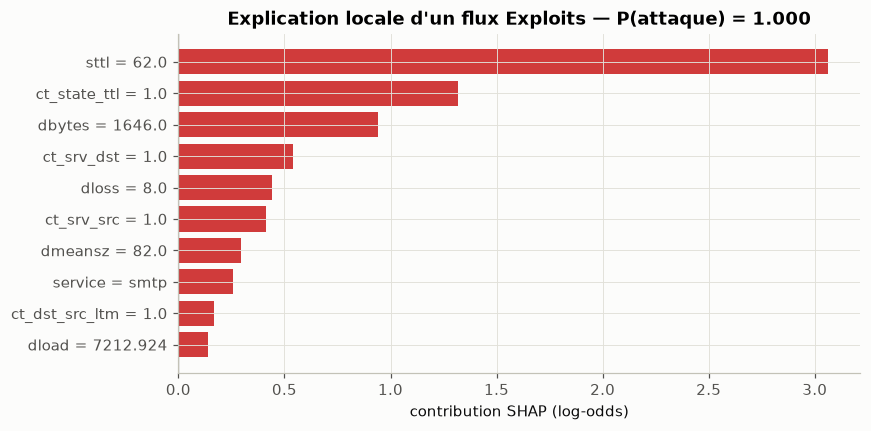

Le modèle classe ce flux comme une ATTAQUE (probabilité d'attaque 100.0%, confiance très élevée). Catégorie d'attaque la plus probable : **Exploits**. Éléments qui poussent vers « attaque » : sttl = 62 (TTL source → destination) ; ct_state_ttl = 1 (Code état × plages de TTL (Algorithme 3.3)) ; dbytes = 1646 (Octets destination → source).


In [5]:
row = test[test.attack_cat == 'Exploits'].sample(1, random_state=0)
ex = EX.explain_instance(xgb, row, top=10)
c = pd.DataFrame(ex['contributions'])
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(c.feature + ' = ' + c.value.astype(str).str[:8], c.contribution, color=[V.ATTACK if v > 0 else V.NORMAL for v in c.contribution])
ax.invert_yaxis(); ax.axvline(0, color='#52514e', lw=0.8); ax.set_xlabel('contribution SHAP (log-odds)')
ax.set_title(f"Explication locale d'un flux Exploits — P(attaque) = {ex['probability']:.3f}")
V.save(fig, '06_shap_local'); plt.show()
print(EX.text_explanation(int(ex['probability'] > 0.5), ex['probability'], 'Exploits', ex['contributions']))

## SHAP par catégorie et ablation par groupe de features (Tables 3.11 à 3.14 de la thèse)

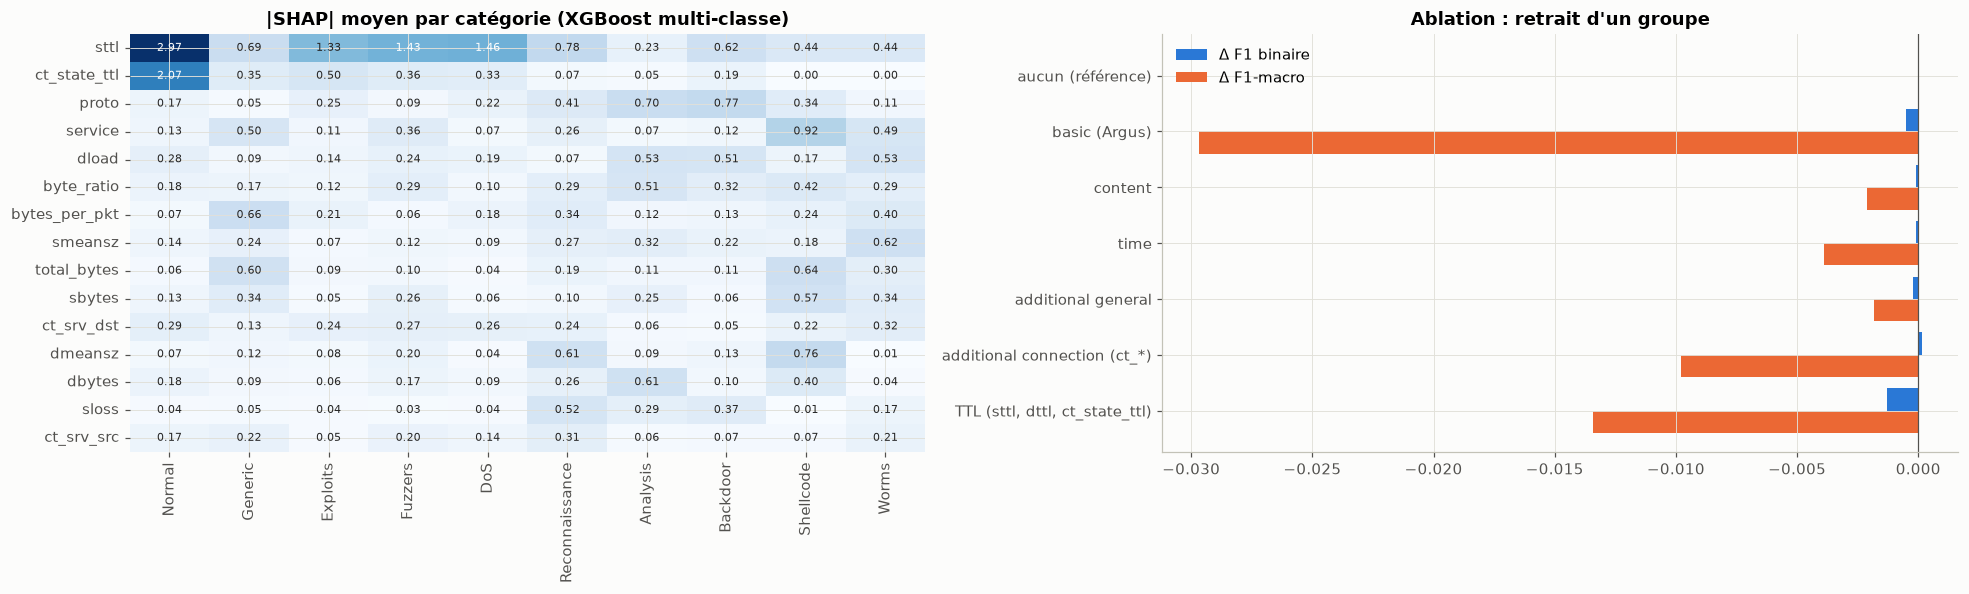

,removed_group,n_removed,f1_binary,f1_multiclass,delta_binary,delta_multiclass
0,aucun (référence),0,0.9879,0.6825,0.0000,0.0000
1,basic (Argus),13,0.9874,0.6528,-0.0005,-0.0297
2,content,6,0.9878,0.6804,-0.0001,-0.0021
3,time,7,0.9878,0.6786,-0.0001,-0.0039
4,additional general,5,0.9876,0.6807,-0.0002,-0.0018
5,additional connection (ct_*),7,0.9880,0.6727,0.0001,-0.0098
6,"TTL (sttl, dttl, ct_state_ttl)",3,0.9866,0.6691,-0.0013,-0.0134


In [6]:
sh = pd.read_csv(C.METRICS_DIR / 'shap_multiclass_by_category.csv', index_col=0)
top = sh.sum(1).sort_values(ascending=False).index[:15]
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
sns.heatmap(sh.loc[top], cmap=V.SEQ_CMAP, ax=axes[0], annot=True, fmt='.2f', annot_kws={'size': 7}, cbar=False)
axes[0].set_title('|SHAP| moyen par catégorie (XGBoost multi-classe)')
ab = pd.read_csv(C.METRICS_DIR / 'ablation_feature_groups.csv')
y = np.arange(len(ab))
axes[1].barh(y - 0.2, ab.delta_binary, 0.4, label='Δ F1 binaire', color=V.SERIES[0]); axes[1].barh(y + 0.2, ab.delta_multiclass, 0.4, label='Δ F1-macro', color=V.SERIES[1])
axes[1].set_yticks(y, ab.removed_group); axes[1].invert_yaxis(); axes[1].axvline(0, color='#52514e', lw=0.8); axes[1].legend(); axes[1].set_title('Ablation : retrait d\'un groupe')
plt.tight_layout(); V.save(fig, '06_shap_category_ablation'); plt.show()
display(ab.round(4))

**Conclusions :**
- Consensus des cinq méthodes : `sttl` / `ct_state_ttl`, la taille moyenne des paquets (`smeansz`, `dmeansz`),
  les volumes (`sbytes`, `dbytes`), les compteurs de connexion `ct_*` et `service`.
- SHAP par catégorie : *Generic* s'appuie sur `ct_srv_src`/`service`, *Reconnaissance* sur l'état et la durée, etc.
- L'ablation montre la **redondance** : retirer un groupe coûte peu car d'autres variables portent la même
  information — sauf pour la tâche multi-classe, plus exigeante.